<a href="https://colab.research.google.com/github/BenFreilichUVA/walmart-hurricane-project/blob/main/notebooks/scratch/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###WALMART MIDTERM PROJECT

First, we need to clone the repo so we can actually pull the data and work on the project. Then, we need to load the raw data and put it into pandas DataFrames so the data can be manipulated and changed around. There are five raw files in the data folder that need to be converted.

'walmart_transactions.csv', turned into 'transactions'

'store_locations.csv', turned into 'stores'

'product_catalog.csv', turned into 'products'

'distribution_centers.csv', turned into 'centers'

'inventory_and_sales_db', turned into 'daily_sales' and 'inventory'




In [24]:
!rm -rf /content/walmart-hurricane-project
!git clone https://github.com/BenFreilichUVA/walmart-hurricane-project.git /content/walmart-hurricane-project

from pathlib import Path

def check_repo(root):
    root = Path(root)
    needed = ['CHARTER.md', 'README.md', 'data', 'notebooks/team_notebook.ipynb', 'notebooks/scratch']
    ok = True
    for item in needed:
        found = (root / item).exists()
        print('PASS' if found else 'FAIL', '-', item)
        ok = ok and found
    print()
    print('repo ready:', ok)
    return ok

MY_REPO = '/content/walmart-hurricane-project'
check_repo(MY_REPO)

Cloning into '/content/walmart-hurricane-project'...
remote: Enumerating objects: 73, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 73 (delta 29), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (73/73), 1.23 MiB | 6.15 MiB/s, done.
Resolving deltas: 100% (29/29), done.
PASS - CHARTER.md
PASS - README.md
PASS - data
PASS - notebooks/team_notebook.ipynb
PASS - notebooks/scratch

repo ready: True


True

In [25]:
DATA = Path(MY_REPO) / 'data'

import pandas as pd
import sqlite3
transactions = pd.read_csv(DATA / 'walmart_transactions.csv')
stores       = pd.read_csv(DATA / 'store_locations.csv')
products     = pd.read_csv(DATA / 'product_catalog.csv')
centers          = pd.read_csv(DATA / 'distribution_centers.csv')

conn = sqlite3.connect(DATA / 'inventory_and_sales.db')

daily_sales = pd.read_sql('SELECT * FROM daily_sales_summary', conn)
inventory   = pd.read_sql('SELECT * FROM inventory_levels', conn)

conn.close()

print('transactions', transactions.shape)
print('stores      ', stores.shape)
print('products    ', products.shape)
print('centers     ', centers.shape)
print('daily_sales', daily_sales.shape)
print('inventory   ', inventory.shape)

decision_log = {}


transactions (25562, 8)
stores       (14, 8)
products     (45, 7)
centers      (5, 8)
daily_sales (3600, 5)
inventory    (4320, 6)


### CLEANING

Next, cleaning has to be done. This will take a lot of different steps, and the assignment specifically asks to create a log of each change made.

In [26]:
# Fixing the Store IDS for the transaction DataFrame
def fix_store_ids(df):
    clean = df.copy()
    before = clean['store_id'].nunique()
    clean['store_id'] = (clean['store_id']
                         .str.strip()
                         .str.upper()
                         .str.replace(r'^FL[-_]?', 'FL-', regex=True))
    after = clean['store_id'].nunique()
    # Assertions to ensure this step properly worked
    assert clean['store_id'].nunique() == 12, 'expected 12 stores'
    assert clean['store_id'].str.fullmatch(r'FL-\d{3}').all(), 'some IDs are not in FL-### format'
    assert len(clean) == len(df), 'cleaning should not drop rows'
    decision_log['transactions: store_id'] = f'Standardized store IDs to FL-###, removing unnecessary spacing and uppercasing ({before} spellings condensed to {after} spellings).'
    return clean

# Fixing the Categories for the transaction DataFrame
category_map = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency', 'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics', 'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household', 'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast', 'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks', 'health': 'Health', 'health & wellness': 'Health',
}

def fix_categories(df, db_categories):
    clean = df.copy()
    before = clean['category'].nunique()
    clean['category'] = clean['category'].str.strip().str.lower().map(category_map)
    after = clean['category'].nunique()
    #Assertions to ensure this step properly worked
    assert clean['category'].isna().sum() == 0, 'some categories did not map'
    assert set(clean['category']) == set(db_categories), 'categories do not match the database'
    decision_log['transactions: category'] = f'Mapped category names down to the 10 used in the database ({before} spellings condensed to {after} spellings).'
    return clean

# Fixing the unit_price column to not be stored as text, and to instead be stored as a number
def fix_unit_price(df):
    clean = df.copy()
    dollar_rows = clean['unit_price'].astype(str).str.contains('$', regex=False).sum()

    clean['unit_price'] = pd.to_numeric(
        clean['unit_price'].astype(str).str.replace('$', '', regex=False).str.strip(),
        errors='coerce')

    #Assertions to ensure this step properly worked
    assert clean['unit_price'].isna().sum() == 0, 'some prices did not convert'
    assert (clean['unit_price'] > 0).all(), 'found a zero or negative price'
    decision_log['transactions: unit_price'] = f'Removed $ from {dollar_rows:,} prices and converted the column from text to numbers'
    return clean

# Converting all of the timestamps into the same format
formats = ['%Y-%m-%d %H:%M:%S',   # 2024-09-15 18:36:16
           '%Y-%m-%dT%H:%M:%S',   # 2024-09-25T10:00:08
           '%m/%d/%Y %H:%M',      # 09/28/2024 17:19
           '%m-%d-%Y %H:%M:%S',   # 09-26-2024 17:46:57
           '%d-%b-%Y %H:%M']      # 13-Sep-2024 21:07

def parse_timestamps(df):
    clean = df.copy()
    raw_ts = clean['timestamp'].str.strip()
    missing_ts = raw_ts.isna().sum()

    parsed = pd.Series(pd.NaT, index=raw_ts.index, dtype='datetime64[ns]')
    for f in formats:
        attempt = pd.to_datetime(raw_ts, format=f, errors='coerce')
        parsed = parsed.fillna(attempt)

    clean['timestamp'] = parsed

    unparsed = (clean['timestamp'].isna() & raw_ts.notna()).sum()
    # Assertions to ensure the timestamps are correctly formatted.
    assert unparsed == 0, 'some timestamps did not match any format'
    assert clean['timestamp'].isna().sum() == missing_ts, 'blank count changed'
    assert (clean['timestamp'].dropna().dt.month == 9).all(), 'found a date outside September'

    decision_log['transactions: timestamp'] = (f'Parsed 5 timestamp formats into one datetime column '
                                               f'({missing_ts} rows had no timestamp, handled after duplicates were removed)')
    return clean

# Deleting the duplicates
def drop_duplicate_rows(df):
    rows_before = len(df)
    dup_rows = df.duplicated().sum()

    clean = df.drop_duplicates()

    # Assertions to ensure the duplicates were correctly dropped
    assert len(clean) == rows_before - dup_rows, 'dropped the wrong number of rows'
    assert clean['transaction_id'].is_unique, 'some transaction IDs still repeat'

    decision_log['transactions: duplicates'] = (f'Dropped {dup_rows} exact duplicate rows '
                                                f'({rows_before:,} rows became {len(clean):,})')
    return clean

# Fixing the quantities
def fix_quantities(df):
    rows_before = len(df)
    zero_rows = (df['quantity'] == 0).sum()
    neg_rows = (df['quantity'] < 0).sum()
    # Right now we are keeping the negative rows, assuming that they are returns.
    clean = df[df['quantity'] != 0].copy()
    # Assertions to check that there are no zero quantities left in the dataframe.
    assert (clean['quantity'] != 0).all(), 'zero quantities remain'
    assert len(clean) == rows_before - zero_rows, 'dropped the wrong number of rows'

    clean['is_return'] = clean['quantity'] < 0

    decision_log['transactions: quantity'] = (f'Dropped {zero_rows} rows with quantity 0. '
                                              f'Kept {neg_rows} negative quantities as returns, flagged in is_return.')
    return clean

# Creating a second table to only contain orders that have a timestamp
def make_clean_dated(clean):
    blank = clean['timestamp'].isna()
    blank_rows = blank.sum()

    clean_dated = clean[~blank].copy()
    clean_dated['date'] = clean_dated['timestamp'].dt.normalize()
    # Assertions to make sure the new table deleted all of the blank timestamps and that the dates are in the correct range.
    assert clean_dated['timestamp'].isna().sum() == 0, 'blank timestamps remain'
    assert len(clean_dated) == len(clean) - blank_rows, 'clean_dated has the wrong row count'
    assert clean_dated['date'].between('2024-09-01', '2024-09-30').all(), 'date outside September'

    decision_log['transactions: blank timestamps'] = (
        f'Kept {blank_rows} rows with no timestamp in clean ({blank_rows / len(clean):.1%} of rows). '
        f'Left them out of clean_dated, which is used for daily counts (Q1, Q3). ')
    return clean_dated

def clean_transactions(raw, db_categories):
    steps = [fix_store_ids,
             lambda d: fix_categories(d, db_categories),
             fix_unit_price,
             parse_timestamps,
             drop_duplicate_rows,
             fix_quantities]
    names = ['fix_store_ids', 'fix_categories', 'fix_unit_price', 'parse_timestamps', 'drop_duplicate_rows', 'fix_quantities']
    df = raw
    print(f'{"start":20} {len(df):>6,} rows')
    for name, step in zip(names, steps):
        df = step(df)
        print(f'{name:20} {len(df):>6,} rows')
    return df

clean = clean_transactions(transactions, daily_sales['category'])
clean_dated = make_clean_dated(clean)


for step, note in decision_log.items():
    print(f'{step} - {note}')


start                25,562 rows
fix_store_ids        25,562 rows
fix_categories       25,562 rows
fix_unit_price       25,562 rows
parse_timestamps     25,562 rows
drop_duplicate_rows  25,532 rows
fix_quantities       25,532 rows
transactions: store_id - Standardized store IDs to FL-###, removing unnecessary spacing and uppercasing (60 spellings condensed to 12 spellings).
transactions: category - Mapped category names down to the 10 used in the database (37 spellings condensed to 10 spellings).
transactions: unit_price - Removed $ from 3,029 prices and converted the column from text to numbers
transactions: timestamp - Parsed 5 timestamp formats into one datetime column (886 rows had no timestamp, handled after duplicates were removed)
transactions: duplicates - Dropped 30 exact duplicate rows (25,562 rows became 25,532)
transactions: quantity - Dropped 0 rows with quantity 0. Kept 130 negative quantities as returns, flagged in is_return.
transactions: blank timestamps - Kept 884 row

Looking through the stores file, we see that there are problems including messy IDS, duplicate rows, and overall completeness errors. These will be fixed in the cell below.

In [27]:
def clean_stores(stores, clean):
    stores_clean = stores.copy()

    # Fixing the store IDs, same rule as transactions
    stores_clean['store_id'] = (stores_clean['store_id']
                                .str.strip()
                                .str.upper()
                                .str.replace(r'^FL[-_]?', 'FL-', regex=True))

    # Dropping stores that appear twice once their IDs match
    rows_before = len(stores_clean)
    dup_stores = stores_clean.duplicated('store_id').sum()
    stores_clean = stores_clean.drop_duplicates('store_id').copy()

    # Standardizing state and region text
    states_before = stores_clean['state'].unique().tolist()
    stores_clean['state'] = 'FL'
    stores_clean['region'] = stores_clean['region'].str.strip()

    # Filling in Tallahassee's missing coordinates (city center, same as the other stores use)
    missing_coords = stores_clean.loc[stores_clean['latitude'].isna(), 'store_id'].tolist()
    stores_clean.loc[stores_clean['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]

    # Assertions
    assert len(stores_clean) == 12, 'expected 12 stores'
    assert stores_clean['store_id'].is_unique, 'store IDs repeat'
    assert set(stores_clean['store_id']) == set(clean['store_id']), 'store IDs do not match transactions'
    assert stores_clean[['latitude', 'longitude']].notna().all().all(), 'missing coordinates remain'
    assert stores_clean['region'].nunique() == 6, 'expected 6 regions'

    decision_log['stores: store_id'] = f'Standardized store IDs to FL-### and dropped {dup_stores} duplicate stores ({rows_before} rows became {len(stores_clean)}).'
    decision_log['stores: state'] = f'Set every state to FL (was {states_before}).'
    decision_log['stores: region'] = 'Removed a leading space from " Panhandle" so it matches Panhandle (7 regions condensed to 6).'
    decision_log['stores: coordinates'] = f'Filled missing latitude and longitude for {missing_coords} (Tallahassee) with city-center coordinates.'
    return stores_clean

stores_clean = clean_stores(stores, clean)
print('stores', len(stores), '->', len(stores_clean), 'rows')

stores 14 -> 12 rows


Next is the products DataFrame. Because a lot of this cleaning is less straight forward and requires more judgement calls, a lot of the cleaning here will be saved for Question 2. For now, the cleaning will result on purely objective errors.

In [28]:
def clean_products(products, clean):
    products_clean = products.copy()

    # Fixing categories, reusing the earlier map from the transactions cleaning
    cat_before = products_clean['category'].nunique()
    products_clean['category'] = products_clean['category'].str.strip().str.lower().map(category_map)

    # Standardizing the package_size format to make it more easily comparable
    pkg_before = products_clean['package_size'].nunique()
    products_clean['package_size'] = (products_clean['package_size']
                                      .str.strip().str.lower()
                                      .replace('single', '1pk')
                                      .str.replace(r'^(\d+)\s*-?\s*(pk|pack)$', r'\1-pack', regex=True))

    # Counting what we are deliberately leaving blank
    missing_cost = products_clean['unit_cost'].isna().sum()
    missing_sub = products_clean['subcategory'].isna().sum()

    # Assertions to make sure everything objective that needed to be cleaned worked.
    assert products_clean['category'].isna().sum() == 0, 'some categories did not map'
    assert set(products_clean['category']) == set(clean['category']), 'categories do not match transactions'
    assert set(products_clean['sku']) == set(clean['sku']), 'catalog SKUs do not match transactions'
    assert products_clean['sku'].is_unique, 'SKUs repeat in the catalog'
    assert len(products_clean) == len(products), 'cleaning should not drop rows'

    decision_log['products: category'] = f'Mapped categories to the same 10 as transactions ({cat_before} spellings condensed to 10).'
    decision_log['products: package_size'] = (f'Standardized format to "#-pack" ({pkg_before} spellings condensed to '
                                              f'{products_clean["package_size"].nunique()}). Values contradict product names '
                                              f'(water 24PK listed as 1-pack), so not used in analysis.')
    decision_log['products: supplier'] = 'Left as is. Suppliers do not match products (Roku Inc for Pop-Tarts), so not used in analysis.'
    decision_log['products: missing values'] = (f'Left {missing_cost} missing unit_cost and {missing_sub} missing subcategory blank. '
                                                f'Filling them would mean guessing.')
    decision_log['products: duplicate products'] = 'Kept all 45 SKUs. Several SKUs are the same product, which is Q2, so they are not merged here.'
    return products_clean

products_clean = clean_products(products, clean)
print('products', len(products), '->', len(products_clean), 'rows')

products 45 -> 45 rows


Next we have to fix the Centers Dataframe. Surge capacity was listed as text, and missing shipping costs had to be addressed.

In [29]:
def clean_centers(centers):
    centers_clean = centers.copy()

    # Fixing surge_capacity, which is text because Miami's value is '~750'
    approx_dcs = centers_clean.loc[centers_clean['surge_capacity'].astype(str).str.contains('~', regex=False), 'dc_id'].tolist()
    centers_clean['surge_capacity'] = pd.to_numeric(
        centers_clean['surge_capacity'].astype(str).str.replace('~', '', regex=False).str.strip(),
        errors='coerce')

    # Counting the missing shipping cost we are leaving blank
    missing_cost_dcs = centers_clean.loc[centers_clean['cost_per_shipment'].isna(), 'dc_id'].tolist()

    # Assertions
    assert centers_clean['surge_capacity'].isna().sum() == 0, 'some surge capacities did not convert'
    assert (centers_clean['surge_capacity'] >= centers_clean['avg_daily_shipments']).all(), 'surge capacity below normal shipments'
    assert centers_clean['dc_id'].is_unique, 'distribution centers repeat'
    assert len(centers_clean) == len(centers), 'cleaning should not drop rows'

    decision_log['centers: surge_capacity'] = (f'Removed ~ and converted to numbers. {approx_dcs} was listed as approximate (~750), '
                                               f'kept as 750 but treated as an estimate.')
    # For now we have to leave it as blank because we are unsure. However, we could try to fill this with an estimated model using the other datapoints.
    decision_log['centers: cost_per_shipment'] = (f'Left missing cost for {missing_cost_dcs} (Birmingham) blank. '
                                                  f'Filling it would mean guessing.')
    return centers_clean

centers_clean = clean_centers(centers)
print('centers', len(centers), '->', len(centers_clean), 'rows')

centers 5 -> 5 rows


Next we have to clean the sales DataFrame. The date format is incorrect and needs to be matched to the other DataFrames, so that is where we will start. The negative revenue on positive units is currently being treated as an error. Negative revenue on negative units would make sense as a return, however inverse signs does not make sense. Finally, we have half units, which does not make sense. For now we will merely flag them and leave them as they are.

In [30]:
def clean_sales(daily_sales):
    sales_clean = daily_sales.copy()

    # Fixing dates: removing the dashes makes every date YYYYMMDD, then converting to datetime
    nodash_dates = (sales_clean['date'].str.len() == 8).sum()
    sales_clean['date'] = pd.to_datetime(sales_clean['date'].str.replace('-', '', regex=False), format='%Y%m%d')

    # Fixing negative revenue by flipping the sign and flagging which ones were flipped.
    sales_clean['revenue_sign_fixed'] = sales_clean['total_revenue'] < 0
    neg_revenue = sales_clean['revenue_sign_fixed'].sum()
    sales_clean['total_revenue'] = sales_clean['total_revenue'].abs()

    # Flagging half units rather than rounding randomly.
    sales_clean['half_unit'] = sales_clean['total_units'] % 1 != 0
    half_units = sales_clean['half_unit'].sum()

    # Assertions to make sure the date range is okay, there are no duplicates in the sales, and there are no lines with negative total revenue.
    assert sales_clean['date'].between('2024-09-01', '2024-09-30').all(), 'date outside September'
    assert sales_clean['date'].nunique() == 30, 'expected 30 days'
    assert not sales_clean.duplicated(['date', 'store_id', 'category']).any(), 'a store and category repeat on the same day'
    assert len(sales_clean) == 30 * 12 * 10, 'expected one row per day, store, and category'
    assert (sales_clean['total_revenue'] >= 0).all(), 'negative revenue remains'

    decision_log['daily_sales: date'] = f'Converted {nodash_dates} YYYYMMDD dates and the rest to one datetime column.'
    decision_log['daily_sales: total_revenue'] = (f'Flipped the sign on {neg_revenue} negative revenues. Units were positive and '
                                                  f'revenue per unit matched other rows, so these look like sign errors. Flagged in revenue_sign_fixed.')
    decision_log['daily_sales: total_units'] = f'Left {half_units} half-unit values as is (rounding would be a guess). Flagged in half_unit.'
    return sales_clean

sales_clean = clean_sales(daily_sales)
print('daily_sales', len(daily_sales), '->', len(sales_clean), 'rows')

daily_sales 3600 -> 3600 rows


Finally, we have to clean the inventory table. It needs the date format fixed, the SKUs to be flagged if they are not in the product catalog, and the missing orders.

In [31]:
def clean_inventory(inventory, products_clean, stores_clean):
    inventory_clean = inventory.copy()

    # Converting dates from text to datetime
    inventory_clean['date'] = pd.to_datetime(inventory_clean['date'], format='%Y-%m-%d')

    # Flagging SKUs that are not in the product catalog
    inventory_clean['in_catalog'] = inventory_clean['sku'].isin(products_clean['sku'])
    unknown_skus = sorted(inventory_clean.loc[~inventory_clean['in_catalog'], 'sku'].unique())
    unknown_rows = (~inventory_clean['in_catalog']).sum()

    # Counting missing units_on_order, which we are leaving blank
    missing_orders = inventory_clean['units_on_order'].isna().sum()

    # Assertions to ensure the date format and range are correct, and various variables match everything in the other cleaned tables.
    assert inventory_clean['date'].between('2024-09-01', '2024-09-30').all(), 'date outside September'
    assert inventory_clean['date'].nunique() == 30, 'expected 30 days'
    assert set(inventory_clean['store_id']) == set(stores_clean['store_id']), 'store IDs do not match stores'
    assert not inventory_clean.duplicated(['date', 'store_id', 'sku']).any(), 'a SKU repeats in the same store on the same day'
    assert (inventory_clean['units_on_hand'] >= 0).all(), 'negative stock on hand'
    assert len(inventory_clean) == len(inventory), 'cleaning should not drop rows'

    decision_log['inventory: date'] = 'Converted dates from text to datetime.'
    decision_log['inventory: unknown SKUs'] = (f'Kept {unknown_rows} rows for {len(unknown_skus)} SKUs not in the catalog {unknown_skus}. '
                                               f'Flagged in in_catalog so they can be excluded from product-level analysis.')
    decision_log['inventory: units_on_order'] = (f'Left {missing_orders} missing values blank. Not filled with 0, '
                                                 f'because 0 already means nothing on order.')
    return inventory_clean

inventory_clean = clean_inventory(inventory, products_clean, stores_clean)
print('inventory', len(inventory), '->', len(inventory_clean), 'rows')
print()

for step, note in decision_log.items():
    print(f'{step} - {note}')

inventory 4320 -> 4320 rows

transactions: store_id - Standardized store IDs to FL-###, removing unnecessary spacing and uppercasing (60 spellings condensed to 12 spellings).
transactions: category - Mapped category names down to the 10 used in the database (37 spellings condensed to 10 spellings).
transactions: unit_price - Removed $ from 3,029 prices and converted the column from text to numbers
transactions: timestamp - Parsed 5 timestamp formats into one datetime column (886 rows had no timestamp, handled after duplicates were removed)
transactions: duplicates - Dropped 30 exact duplicate rows (25,562 rows became 25,532)
transactions: quantity - Dropped 0 rows with quantity 0. Kept 130 negative quantities as returns, flagged in is_return.
transactions: blank timestamps - Kept 884 rows with no timestamp in clean (3.5% of rows). Left them out of clean_dated, which is used for daily counts (Q1, Q3). 
stores: store_id - Standardized store IDs to FL-### and dropped 2 duplicate stores (1

Everything below this markdown cell will now use the cleaned tables from above. The helper functions and settings used in the cell below will be used for our questions, and defining them here make it much easier for us when actually doing the questions. Additionally, returns were left out of the demand counts, as a return is not the same as stockpiling, and they are not predictable or significant given the quantity.

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

LANDFALL = pd.Timestamp('2024-09-26')
BASELINE = ('2024-09-08', '2024-09-15')
SURGE    = ('2024-09-23', '2024-09-25')

# Colors used by every chart, assigned in a fixed order so a product keeps its color across charts
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
MUTED  = '#8a8980'

# Helper Function to turn the chart title into words instead of just a number
def days_text(n):
    return 'the day' if n == 1 else f'{n} days'
# Helper function to keep only the rows between two dates to help condense the charts for accuracy.
def window(df, start, end):
    return df[(df['date'] >= start) & (df['date'] <= end)]
# Helper function to style the chart to make it look better.
def tidy(ax, dates=False):
    if dates:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.grid(axis='y', color='#e1e0d9', linewidth=0.8)
    ax.set_axisbelow(True)

# Purchases only to ensure returns are not throwing off the numbers
purchases = clean_dated[~clean_dated['is_return']].copy()

decision_log['analysis: windows'] = f'Baseline {BASELINE[0]} to {BASELINE[1]}, surge {SURGE[0]} to {SURGE[1]}, landfall {LANDFALL.date()}.'
decision_log['analysis: purchases only'] = (f'Left {clean_dated["is_return"].sum()} returns out of demand counts '
                                            f'({len(purchases):,} purchase rows used).')
print('purchase rows used:', f'{len(purchases):,}')

purchase rows used: 24,521


## Product Families (SKU CONSOLIDATION)

Below is the mapping for all of the various SKUs for the project. Doing it here makes it easier for the rest of the project. Each family is a judgement call done by hand. The assertions are not able to necessarily check that they were grouped correctly, rather that they were just grouped once, and that every SKU was mapped.

The group with the most subjectivity is the Roku Streaming Stick. The two product SKUs, "STREAM-01" and "ROKU-STD". The roku streaming stick and the roku TV are two different products, however we cannot tell from the SKUs whether ROKU-STD is roku streaming device or something else. Therefore, tit is best to just group them, as there is not really a seperate electornics category. We can infer that all 4 of the SKUs categorized in Pop-Tarts Strawberry because the prices are all identical, and they are all under the breakfast category.

In [33]:
product_families = {
    'Pop-Tarts Strawberry':   ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY'],
    'Bottled Water 24-Pack':  ['WTR-24', 'WATER24PK', 'WTR_24PK'],
    'AA Batteries 4-Pack':    ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK'],
    'Monopoly Board Game':    ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO'],
    'LED Flashlight':         ['FLASH-01', 'LED-FLASH'],
    'Light Beer 24-Pack':     ['BEER-24', 'LTBEER24'],
    'Playing Cards':          ['CARDS-01', 'PLAYCARD-STD'],
    'Roku Streaming Stick':   ['STREAM-01', 'ROKU-STD'],
    'Canned Soup':            ['SOUP-CAN', 'CNSOUP-01'],
    'White Bread':            ['BREAD-WH', 'WHITEBREAD'],
    'Peanut Butter':          ['PB-16', 'PNUTBTR-16'],
    'Emergency Candles':      ['CNDL-EM', 'CANDLE-EMRG'],
    'First Aid Kit':          ['FAID-01', 'FIRSTAID-KIT'],
    'Portable Phone Charger': ['CHRG-PORT', 'PORTCHARGER'],
    'Chips Variety Pack':     ['CHIPS-VP', 'CHIPVARIETY'],
    'Paper Towels':           ['PTOWEL-6', 'PAPERTOWEL6'],
    'Toilet Paper 12-Roll':   ['TP-12', 'TOILETPAPER12'],
    'Baby Diapers Size 3':    ['DIAP-S3', 'DIAPERS-3'],
    'Baby Formula':           ['BFORM-01', 'BABYFORMULA'],
    'Heavy Duty Tarp':        ['TARP-HD', 'HDTARP-01'],
}

# Flipping it so each SKU looks up its product
sku_to_product = {sku: product for product, skus in product_families.items() for sku in skus}
products_clean['product'] = products_clean['sku'].map(sku_to_product)
purchases['product'] = purchases['sku'].map(sku_to_product)

# Assertions to make sure every SKU is mapped exactly once and every group makes sense
all_mapped = [sku for skus in product_families.values() for sku in skus]
assert len(all_mapped) == len(set(all_mapped)), 'a SKU is mapped to more than one product'
assert set(all_mapped) == set(products_clean['sku']), 'mapping does not cover the catalog exactly'
assert purchases['product'].notna().all(), 'some transaction SKUs are not mapped'
assert (products_clean.groupby('product')['category'].nunique() == 1).all(), 'a product group mixes categories'

group_sizes = products_clean.groupby('product')['sku'].nunique().sort_values(ascending=False)
decision_log['products: families'] = (f'Mapped {products_clean["sku"].nunique()} SKUs to {len(product_families)} products by hand. '
                                      f'Roku and formula pairs grouped on matching category, subcategory, and cost.')

print('distinct SKUs to start:    ', products_clean['sku'].nunique())
print('canonical products now:    ', products_clean['product'].nunique())
print('largest consolidated group:', group_sizes.index[0], f'({group_sizes.iloc[0]} SKUs)')

distinct SKUs to start:     45
canonical products now:     20
largest consolidated group: Pop-Tarts Strawberry (4 SKUs)


Below is the call for the weather API and fix for only receiving the Orlando data on the first checkpoint. By creating the function and making it dependent on latitude and longitude, we are able to examine the effects of the hurricane on all different stores in the area.

In [34]:
import requests, time

# Open-Meteo Historical Weather API (free, no key): https://open-meteo.com/
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat, lon, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'hourly': 'windspeed_10m,precipitation,pressure_msl',
        'timezone': 'America/New_York',            # hours come back in Eastern time, same as the store sales
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        hourly = pd.DataFrame(r.json()['hourly'])
        hourly['time'] = pd.to_datetime(hourly['time'])

        # Hourly readings rolled up to one row per day: rain sums, wind takes the max, pressure takes the lowest reading
        daily = (hourly.groupby(hourly['time'].dt.date)
                 .agg(precipitation_sum=('precipitation', 'sum'),
                      windspeed_max=('windspeed_10m', 'max'),
                      pressure_min=('pressure_msl', 'min'))
                 .reset_index()
                 .rename(columns={'time': 'date'}))
        daily['date'] = pd.to_datetime(daily['date'])
        daily['source'] = 'open-meteo'
        return daily



Here I am calling every store using their distinct store_ids. This pulls every day of data from September 1-30th for all 12 stores. It also contains the backup data in case the weather API is down.


In [35]:
WEATHER_FILE = DATA / 'weather_by_store.csv'

try:
    frames = []
    for s in stores_clean.itertuples():
        w = daily_weather('2024-09-01', '2024-09-30', lat=s.latitude, lon=s.longitude)
        w['store_id'] = s.store_id
        frames.append(w)
        time.sleep(1)                              # be polite to the API
    weather_all = pd.concat(frames, ignore_index=True)
    weather_all.to_csv(WEATHER_FILE, index=False)   # saved copy for when the API is down
except requests.RequestException as err:
    print('API call failed:', err)
    if not WEATHER_FILE.exists():
        raise
    weather_all = pd.read_csv(WEATHER_FILE, parse_dates=['date'])
    weather_all['source'] = 'saved copy of an earlier open-meteo pull'

assert len(weather_all) == 12 * 30, 'expected 12 stores x 30 days'
assert weather_all['store_id'].nunique() == 12, 'a store is missing'
assert weather_all['date'].nunique() == 30, 'a day is missing'

decision_log['weather: source'] = (f'Pulled hourly wind, rain, and pressure for all 12 stores from Open-Meteo '
                                   f'({weather_all["source"].iloc[0]}) and rolled them up to {len(weather_all)} store-days.')
decision_log['weather: timezone'] = ('Requested weather in America/New_York time so its dates match the store-local '
                                     'sales timestamps, which were cut to dates with .dt.normalize().')
print('rows:', len(weather_all), '| source:', weather_all['source'].iloc[0])
weather_all.head()

rows: 360 | source: open-meteo


,date,precipitation_sum,windspeed_max,pressure_min,source,store_id
0,2024-09-01,6.4,18.7,1012.8,open-meteo,FL-239
1,2024-09-02,22.0,12.7,1013.0,open-meteo,FL-239
2,2024-09-03,32.7,20.6,1014.3,open-meteo,FL-239
3,2024-09-04,21.1,12.6,1016.5,open-meteo,FL-239
4,2024-09-05,20.7,15.2,1014.8,open-meteo,FL-239


**Joining the weather data with the sales data using a left join merge.**

In [40]:
# One row per day: weather averaged across the 12 stores, sales added up across the 12 stores
weather_daily = (weather_all.groupby('date')
                 .agg(precipitation_sum=('precipitation_sum', 'mean'),
                      windspeed_max=('windspeed_max', 'mean'),
                      pressure_min=('pressure_min', 'mean'))
                 .reset_index())
sales_daily = (purchases.groupby('date')
               .agg(units=('quantity', 'sum'), orders=('transaction_id', 'size'))
               .reset_index())

merged = sales_daily.merge(weather_daily, on='date', how='left', indicator=True, validate='many_to_one')

assert len(merged) == len(sales_daily), 'the join changed the row count'
assert (merged['_merge'] == 'both').all(), 'some sales days have no weather'
assert merged['units'].sum() == purchases['quantity'].sum(), 'the units total changed'

decision_log['weather: join'] = (f'Left-joined daily weather (averaged across stores) to {len(sales_daily)} days of sales on date. '
                                 f'{len(merged)} rows after, none lost.')
print(merged['_merge'].value_counts())
merged = merged.drop(columns='_merge')
merged.head()

_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64


,date,units,orders,precipitation_sum,windspeed_max,pressure_min
0,2024-09-01,1060,549,8.241667,16.166667,1012.450000
1,2024-09-02,1168,585,7.533333,14.008333,1012.500000
2,2024-09-03,1162,581,13.450000,17.266667,1013.866667
3,2024-09-04,1115,571,14.533333,17.541667,1016.266667
4,2024-09-05,1076,570,11.133333,16.625000,1014.916667


##QUESTION 1: DEMAND SURGE

**Did sales rise ahead of landfall, and by how much against a normal baseline?**

First we look at the sales for all orders, and then we measure each product against its own baseline.

In [36]:
daily_orders = purchases.groupby('date').size().rename('orders')
base_orders = window(daily_orders.reset_index(), *BASELINE)['orders'].mean()
surge_orders = window(daily_orders.reset_index(), *SURGE)['orders'].mean()
order_multiple = surge_orders / base_orders

print(f'baseline: {base_orders:,.0f} orders/day ({BASELINE[0]} to {BASELINE[1]})')
print(f'surge:    {surge_orders:,.0f} orders/day ({SURGE[0]} to {SURGE[1]})')
print(f'multiple: {order_multiple:.1f}x')

baseline: 579 orders/day (2024-09-08 to 2024-09-15)
surge:    1,776 orders/day (2024-09-23 to 2024-09-25)
multiple: 3.1x


In [37]:
# Units per product per day, then each product's surge against its own baseline
daily_units = purchases.groupby(['date', 'product'])['quantity'].sum().unstack(fill_value=0)

base_units = daily_units.loc[BASELINE[0]:BASELINE[1]].mean()
surge_units = daily_units.loc[SURGE[0]:SURGE[1]].mean()

product_surge = pd.DataFrame({
    'baseline_units_per_day': base_units.round(1),
    'surge_units_per_day': surge_units.round(1),
    'multiple': (surge_units / base_units).round(2),
}).sort_values('multiple', ascending=False)

top_product = product_surge.index[0]
top_multiple = product_surge['multiple'].iloc[0]
print('top mover:', top_product, f'at {top_multiple:.1f}x baseline')
product_surge

top mover: Pop-Tarts Strawberry at 7.2x baseline


,baseline_units_per_day,surge_units_per_day,multiple
product,,,
Pop-Tarts Strawberry,73.1,527.0,7.21
LED Flashlight,55.8,234.7,4.21
Bottled Water 24-Pack,98.8,405.3,4.10
Heavy Duty Tarp,46.6,175.3,3.76
Monopoly Board Game,42.9,154.7,3.61
AA Batteries 4-Pack,92.5,328.3,3.55
Emergency Candles,58.1,196.3,3.38
Portable Phone Charger,41.4,138.3,3.34
First Aid Kit,41.0,128.7,3.14


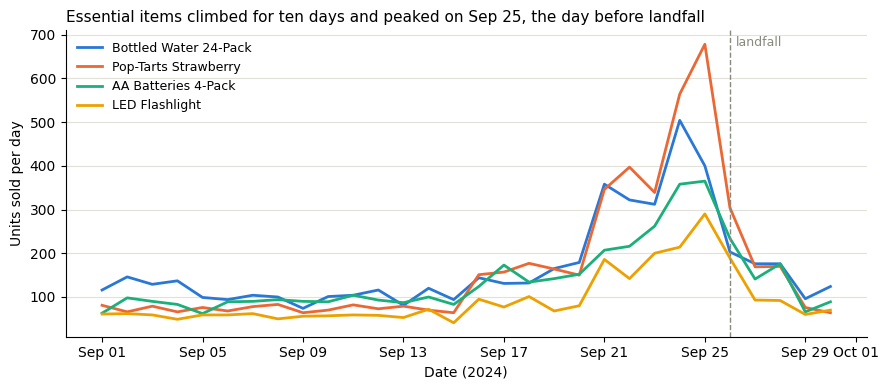

In [38]:
# Pattern 1: raw units for the four products the storm story is about
focus = ['Bottled Water 24-Pack', 'Pop-Tarts Strawberry', 'AA Batteries 4-Pack', 'LED Flashlight']
peak_day = daily_units[focus].sum(axis=1).idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
for product, color in zip(focus, COLORS):
    ax.plot(daily_units.index, daily_units[product], color=color, linewidth=2, label=product)
ax.axvline(LANDFALL, linestyle='--', color=MUTED, linewidth=1)
ax.annotate('landfall', xy=(LANDFALL, ax.get_ylim()[1] * 0.95), xytext=(4, 0),
            textcoords='offset points', fontsize=9, color=MUTED)
days_before = (LANDFALL - peak_day).days
ax.set_title(f'Essential items climbed for ten days and peaked on {peak_day:%b %d}, {days_text(days_before)} before landfall',
             loc='left', fontsize=11)
ax.set_xlabel('Date (2024)')
ax.set_ylabel('Units sold per day')
ax.legend(frameon=False, fontsize=9)
tidy(ax, dates=True)
plt.tight_layout()
plt.show()

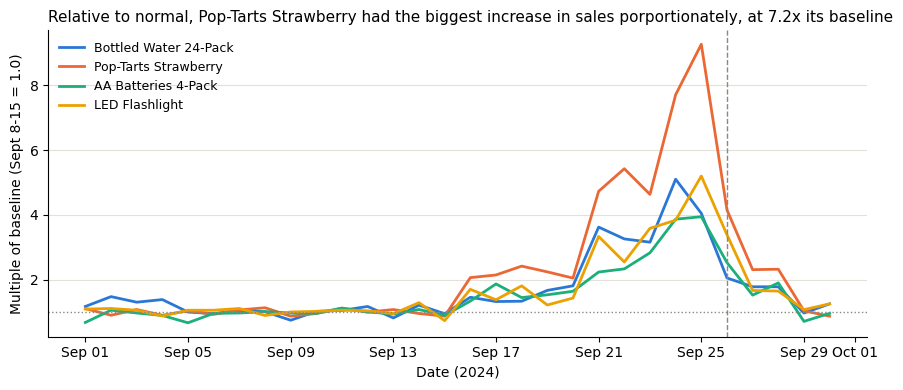

In [39]:
# Pattern 2: the same four products indexed to their own baseline, so each starts at 1.0
indexed = daily_units[focus] / base_units[focus]
lead = indexed.loc[SURGE[0]:SURGE[1]].mean().idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
for product, color in zip(focus, COLORS):
    ax.plot(indexed.index, indexed[product], color=color, linewidth=2, label=product)
ax.axhline(1.0, linestyle=':', color=MUTED, linewidth=1)
ax.axvline(LANDFALL, linestyle='--', color=MUTED, linewidth=1)
ax.set_title(f'Relative to normal, {lead} had the biggest increase in sales porportionately, at {product_surge.loc[lead, "multiple"]:.1f}x its baseline',
             loc='left', fontsize=11)
ax.set_xlabel('Date (2024)')
ax.set_ylabel('Multiple of baseline (Sept 8-15 = 1.0)')
ax.legend(frameon=False, fontsize=9)
tidy(ax, dates=True)
plt.tight_layout()
plt.show()

As we can see from the charts and the table, sales increased. Overall orders ran at around 3.1x the baseline of sales right before the hurricane from Sept 23 to 25. The four essential products peaked right before landfall, and fell back towards baseline after landfall, ending up around baseline after September 29th.

While bottled water outsold flashlights as a whole throughout the hurricane, however in terms of multiples, flashlights and water bottles increased by roughly the same multiple. This is because flashlights were already selling less than bottled water before the hurricane.

Pop-Tarts was the leader on both raw sales and the multiple chart.

The smallest movers were chips and diapers. This shows that the surge was concentrated in specific storm items. I am a little confused as to why chips didn't move as much as pop tarts did. Pop-tarts do not have more nutritional value than chips, yet they rocketed off of their baseline, while chips only doubled.



***Question 3: Weather Correlation Analysis***

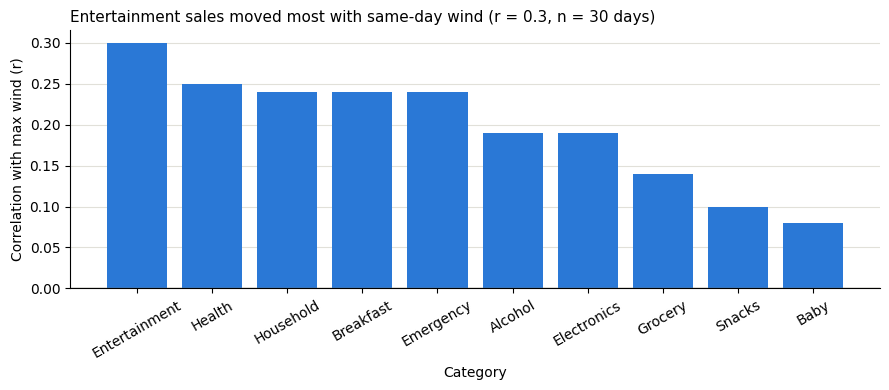

,category,days,Max wind,Rainfall,Lowest pressure
5,Entertainment,30,0.30,-0.23,-0.29
7,Health,30,0.25,-0.31,-0.26
8,Household,30,0.24,-0.28,-0.24
2,Breakfast,30,0.24,-0.29,-0.25
4,Emergency,30,0.24,-0.32,-0.25
0,Alcohol,30,0.19,-0.33,-0.18
3,Electronics,30,0.19,-0.35,-0.20
6,Grocery,30,0.14,-0.38,-0.16
9,Snacks,30,0.10,-0.19,-0.02
1,Baby,30,0.08,-0.51,-0.12


In [41]:
WEATHER_COLS = {'windspeed_max': 'Max wind', 'precipitation_sum': 'Rainfall', 'pressure_min': 'Lowest pressure'}

category_daily = purchases.groupby(['date', 'category'])['quantity'].sum().reset_index()
category_weather = category_daily.merge(weather_daily, on='date', how='left', validate='many_to_one')

rows = []
for category in sorted(category_weather['category'].unique()):
    one = category_weather[category_weather['category'] == category]
    row = {'category': category, 'days': len(one)}
    for col, label in WEATHER_COLS.items():
        row[label] = round(one['quantity'].corr(one[col]), 2)
    rows.append(row)
category_corr = pd.DataFrame(rows).sort_values('Max wind', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(category_corr['category'], category_corr['Max wind'], color=COLORS[0])
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xlabel('Category')
ax.set_ylabel('Correlation with max wind (r)')
ax.set_title(f'{category_corr["category"].iloc[0]} sales moved most with same-day wind '
             f'(r = {category_corr["Max wind"].iloc[0]}, n = {category_corr["days"].iloc[0]} days)',
             loc='left', fontsize=11)
ax.tick_params(axis='x', labelrotation=30)
tidy(ax)
plt.tight_layout()
plt.show()
category_corr